
# 📱 Feature Extraction and Price Prediction for Mobile Phones

**Project type:** Regression / Feature Extraction  |  **Dataset:** `Processed_Flipdata.xlsx` (541 listings)  |  **Deadline:** 1 Nov 2026

---

## Project Scenario
An organization that sells mobile phones wants to improve its pricing strategy by understanding **which phone features drive price** in a highly competitive market. In this notebook we:

1. Explore the dataset
2. Clean and preprocess it (missing values, outliers, inconsistencies, encoding)
3. Extract the most influential features (correlation, mutual information, F-test, PCA, model importance)
4. Build and compare several regression models
5. Evaluate them with MAE, RMSE and R²
6. Confirm feature importance with the final model
7. Summarize findings and give business recommendations

## Table of Contents
1. [Setup & Data Loading](#1.-Setup-&-Data-Loading)
2. [Data Exploration](#2.-Data-Exploration)
3. [Data Preprocessing](#3.-Data-Preprocessing)
4. [Exploratory Visualizations](#4.-Exploratory-Visualizations)
5. [Feature Extraction](#5.-Feature-Extraction)
6. [Model Building](#6.-Model-Building)
7. [Model Evaluation](#7.-Model-Evaluation)
8. [Hyperparameter Tuning](#8.-Hyperparameter-Tuning)
9. [Feature Importance Analysis](#9.-Feature-Importance-Analysis)
10. [Report: Findings & Recommendations](#10.-Report:-Findings-&-Recommendations)


## 1. Setup & Data Loading

In [11]:

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.feature_selection import mutual_info_regression, f_regression
from sklearn.decomposition import PCA
from sklearn.inspection import permutation_importance, PartialDependenceDisplay
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.titlesize"] = 13
RANDOM_STATE = 42
pd.set_option("display.max_columns", 50)


In [12]:

# Put Processed_Flipdata.xlsx in the same folder as this notebook (or edit the path).
DATA_PATH = "Processed_Flipdata.xlsx"

df_raw = pd.read_excel(DATA_PATH)
df = df_raw.copy()
print("Shape:", df.shape)
df.head()


Shape: (541, 12)


,Unnamed: 0,Model,Colour,Memory,RAM,Battery_,Rear Camera,Front Camera,AI Lens,Mobile Height,Processor_,Prize
0,0,Infinix SMART 7,Night Black,64,4,6000,13MP,5MP,1,16.76,Unisoc Spreadtrum SC9863A1,7299
1,1,Infinix SMART 7,Azure Blue,64,4,6000,13MP,5MP,1,16.76,Unisoc Spreadtrum SC9863A1,7299
2,2,MOTOROLA G32,Mineral Gray,128,8,5000,50MP,16MP,0,16.64,Qualcomm Snapdragon 680,11999
3,3,POCO C50,Royal Blue,32,2,5000,8MP,5MP,0,16.56,Mediatek Helio A22,5649
4,4,Infinix HOT 30i,Marigold,128,8,5000,50MP,5MP,1,16.76,G37,8999



## 2. Data Exploration
Let's look at the structure, data types, summary statistics, missing values and duplicates.


In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541 entries, 0 to 540
Data columns (total 12 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Unnamed: 0     541 non-null    int64  
 1   Model          541 non-null    object 
 2   Colour         541 non-null    object 
 3   Memory         541 non-null    int64  
 4   RAM            541 non-null    int64  
 5   Battery_       541 non-null    int64  
 6   Rear Camera    541 non-null    object 
 7   Front Camera   541 non-null    object 
 8   AI Lens        541 non-null    int64  
 9   Mobile Height  541 non-null    float64
 10  Processor_     541 non-null    object 
 11  Prize          541 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 50.8+ KB


In [14]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,541.0,289.711645,182.359185,0.0,135.00,273.00,434.00,642.00
Memory,541.0,110.550832,60.600694,16.0,64.00,128.00,128.00,256.00
RAM,541.0,5.397412,1.984923,2.0,4.00,6.00,8.00,8.00
Battery_,541.0,4871.587800,780.148862,800.0,5000.00,5000.00,5000.00,7000.00
AI Lens,541.0,0.062847,0.242911,0.0,0.00,0.00,0.00,1.00
Mobile Height,541.0,16.431201,2.523553,4.5,16.51,16.71,16.94,41.94
Prize,541.0,16228.375231,10793.588322,920.0,9290.00,13499.00,19280.00,80999.00


In [15]:

print("Missing values per column:")
print(df.isna().sum())
print("\nExact duplicate rows (all columns):", df.duplicated().sum())
print("Duplicates ignoring the index column:", df.drop(columns="Unnamed: 0").duplicated().sum())


Missing values per column:
Unnamed: 0       0
Model            0
Colour           0
Memory           0
RAM              0
Battery_         0
Rear Camera      0
Front Camera     0
AI Lens          0
Mobile Height    0
Processor_       0
Prize            0
dtype: int64

Exact duplicate rows (all columns): 0
Duplicates ignoring the index column: 10


In [16]:

# Cardinality of categorical / text columns
cat_cols_raw = df.select_dtypes(include=["object", "string"]).columns
pd.DataFrame({"unique_values": df[cat_cols_raw].nunique(),
              "example": [df[c].iloc[0] for c in cat_cols_raw]})


,unique_values,example
Model,187,Infinix SMART 7
Colour,275,Night Black
Rear Camera,14,13MP
Front Camera,13,5MP
Processor_,123,Unisoc Spreadtrum SC9863A1


In [7]:

print("Rear Camera values:\n", df["Rear Camera"].value_counts().to_dict())
print("\nFront Camera values:\n", df["Front Camera"].value_counts().to_dict())
print("\nSample of raw Processor values:\n", df["Processor_"].drop_duplicates().sample(15, random_state=1).tolist())


Rear Camera values:
 {'50MP': 260, '13MP': 63, '64MP': 62, '8MP': 52, '48MP': 31, '108MP': 31, '0MP': 10, '12MP': 10, '200MP': 8, '2MP': 6, '5MP': 3, '40MP': 2, '32MP': 2, '16MP': 1}

Front Camera values:
 {'16MP': 164, '5MP': 135, '8MP': 129, '13MP': 49, '32MP': 22, '0MP': 16, '50MP': 7, '12MP': 6, '60MP': 4, '2MP': 3, '10MP': 2, '20MP': 2, '44MP': 2}

Sample of raw Processor values:
 ['Unisoc T612 processor', 'Qualcomm Snapdragon 720G', 'Qualcomm Snapdragon 778G+', 'ios', 'Qualcomm Snapdragon 778G', 'Mediatek Helio G99 Octa Core', 'MediaTek Helio G88', 'MediaTek Dimensity 700', 'Qualcomm Snapdragon 855', 'Mediatek Helio G88', 'IOS', 'MediaTek', 'QualcommÂ® Snapdragonâ_x0084_¢ 765G', 'MediaTek Helio G70', 'Qualcomm Snapdragon 855+']



**Observations**

- There are **no null values**, but the data is *inconsistent*: camera columns are text (`"50MP"`), `Processor_` has 123 spellings of a much smaller set of chips (e.g. `MediaTek` vs `Mediatek`, `Helio G85` vs `MediaTek Helio G85`), and a few entries are not processors at all (`Android`, `Oxygen OS`, `Octa Core`).
- `Model` (187 values) and `Colour` (275 values) are **high-cardinality** – one-hot encoding them directly would create hundreds of sparse columns for only ~540 rows.
- Column names are messy (`Prize`, `Battery_`, `Processor_`) and `Unnamed: 0` is just an old index.
- The same phone appears several times, once per colour, so rows are **not independent** – we must be careful when splitting into train/test (see Section 6).
- `Mobile Height` has a suspicious max of 41.94 and `Battery_` has very low values (800 mAh) – we check these as potential outliers.



## 3. Data Preprocessing

### 3.1 Clean column names and drop the index column


In [17]:

df = df.drop(columns=["Unnamed: 0"])
df = df.rename(columns={
    "Prize": "Price",
    "Battery_": "Battery",
    "Processor_": "Processor",
    "Rear Camera": "Rear_Camera",
    "Front Camera": "Front_Camera",
    "AI Lens": "AI_Lens",
    "Mobile Height": "Height_cm",
    "Memory": "Storage_GB",
})
df.columns.tolist()


['Model',
 'Colour',
 'Storage_GB',
 'RAM',
 'Battery',
 'Rear_Camera',
 'Front_Camera',
 'AI_Lens',
 'Height_cm',
 'Processor',
 'Price']

### 3.2 Fix inconsistencies in text columns

In [18]:

# --- Model: trim spaces and standardise case ---
df["Model"] = df["Model"].str.strip().str.lower()

# --- Brand: first word of the model name (cleaned) ---
df["Brand"] = df["Model"].str.split().str[0]
df["Brand"] = df["Brand"].replace({"micromax1": "micromax", "i": "other"})

# merge very rare brands (< 5 listings) into 'other'
brand_counts = df["Brand"].value_counts()
rare = brand_counts[brand_counts < 5].index
df["Brand"] = df["Brand"].where(~df["Brand"].isin(rare), "other")
df["Brand"].value_counts()


Brand
realme      98
redmi       75
infinix     65
vivo        62
poco        60
samsung     55
motorola    46
tecno       17
oppo        16
micromax    14
other       14
google       9
oneplus      5
apple        5
Name: count, dtype: int64

In [19]:

# --- Camera: '50MP' -> 50 (numeric megapixels) ---
for col in ["Rear_Camera", "Front_Camera"]:
    df[col + "_MP"] = df[col].str.extract(r"(\d+)").astype(float)
df = df.drop(columns=["Rear_Camera", "Front_Camera"])
df[["Rear_Camera_MP", "Front_Camera_MP"]].describe().T


,count,mean,std,min,25%,50%,75%,max
Rear_Camera_MP,541.0,46.110906,31.260416,0.0,13.0,50.0,50.0,200.0
Front_Camera_MP,541.0,11.992606,9.053746,0.0,5.0,8.0,16.0,60.0


In [20]:

# --- Processor: map the 123 spellings to a chip family ---
def processor_family(text):
    t = str(text).lower()
    if "ios" in t or "apple" in t or "bionic" in t:        return "Apple"
    if "tensor" in t:                                       return "Google Tensor"
    if "qualcomm" in t or "snapdragon" in t:                return "Qualcomm Snapdragon"
    if any(k in t for k in ["mediatek", "meditek", "mtk", "dimensity", "helio", "mt62"]) or t.strip() == "g37":
        return "MediaTek"
    if any(k in t for k in ["unisoc", "spreadtrum", "sc98", "sc65"]):  return "Unisoc"
    if "exynos" in t or "sec s5" in t:                      return "Samsung Exynos"
    return "Unknown/Generic"   # 'Octa Core', 'Android', 'Oxygen OS', '6 Core', ...

df["Processor_Family"] = df["Processor"].apply(processor_family)
print(df["Processor_Family"].value_counts())


Processor_Family
MediaTek               285
Qualcomm Snapdragon    130
Unisoc                  71
Samsung Exynos          30
Unknown/Generic         13
Google Tensor            8
Apple                    4
Name: count, dtype: int64


In [21]:

# --- 5G flag (from the model or processor name) ---
df["Is_5G"] = (df["Model"].str.contains("5g") | df["Processor"].str.lower().str.contains("5g")).astype(int)

# --- Colour: reduce 275 marketing names to a base colour family ---
def colour_family(text):
    t = str(text).lower()
    for fam, keys in [("Black",  ["black", "onyx", "obsidian", "midnight", "charcoal", "carbon", "dark matter", "stealth"]),
                      ("White",  ["white", "snow", "chalk", "pearl", "cream", "starlight", "paper"]),
                      ("Blue",   ["blue", "azure", "cyan", "navy", "sea", "ocean", "aqua", "lake"]),
                      ("Green",  ["green", "mint", "olive", "emerald", "jade", "lime", "forest", "rainforest"]),
                      ("Gray",   ["gray", "grey", "graphite", "slate", "meteor"]),
                      ("Silver", ["silver"]),
                      ("Gold",   ["gold", "copper", "peach", "marigold", "sandy"]),
                      ("Purple", ["purple", "violet", "lavender", "iris"]),
                      ("Red/Orange/Yellow/Pink", ["red", "orange", "yellow", "pink", "rose", "scarlet", "flame", "coral", "blush"])]:
        if any(k in t for k in keys):
            return fam
    return "Other"

df["Colour_Family"] = df["Colour"].apply(colour_family)
print(df["Colour_Family"].value_counts())


Colour_Family
Black                     155
Blue                      148
Green                      59
White                      35
Other                      33
Red/Orange/Yellow/Pink     29
Gold                       28
Gray                       20
Purple                     18
Silver                     16
Name: count, dtype: int64



### 3.3 Handle outliers and inconsistent values
We inspect each numeric column with the IQR rule and then decide **case by case** – an outlier is only removed/fixed when it is an *error*, not when it is a genuine (e.g. premium or feature-phone) product.


In [22]:

num_cols = ["Storage_GB", "RAM", "Battery", "Rear_Camera_MP", "Front_Camera_MP", "Height_cm", "Price"]

def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

pd.DataFrame({"n_outliers (IQR rule)": [iqr_outliers(df[c]) for c in num_cols]}, index=num_cols)


,n_outliers (IQR rule)
Storage_GB,55
RAM,0
Battery,152
Rear_Camera_MP,39
Front_Camera_MP,13
Height_cm,33
Price,25


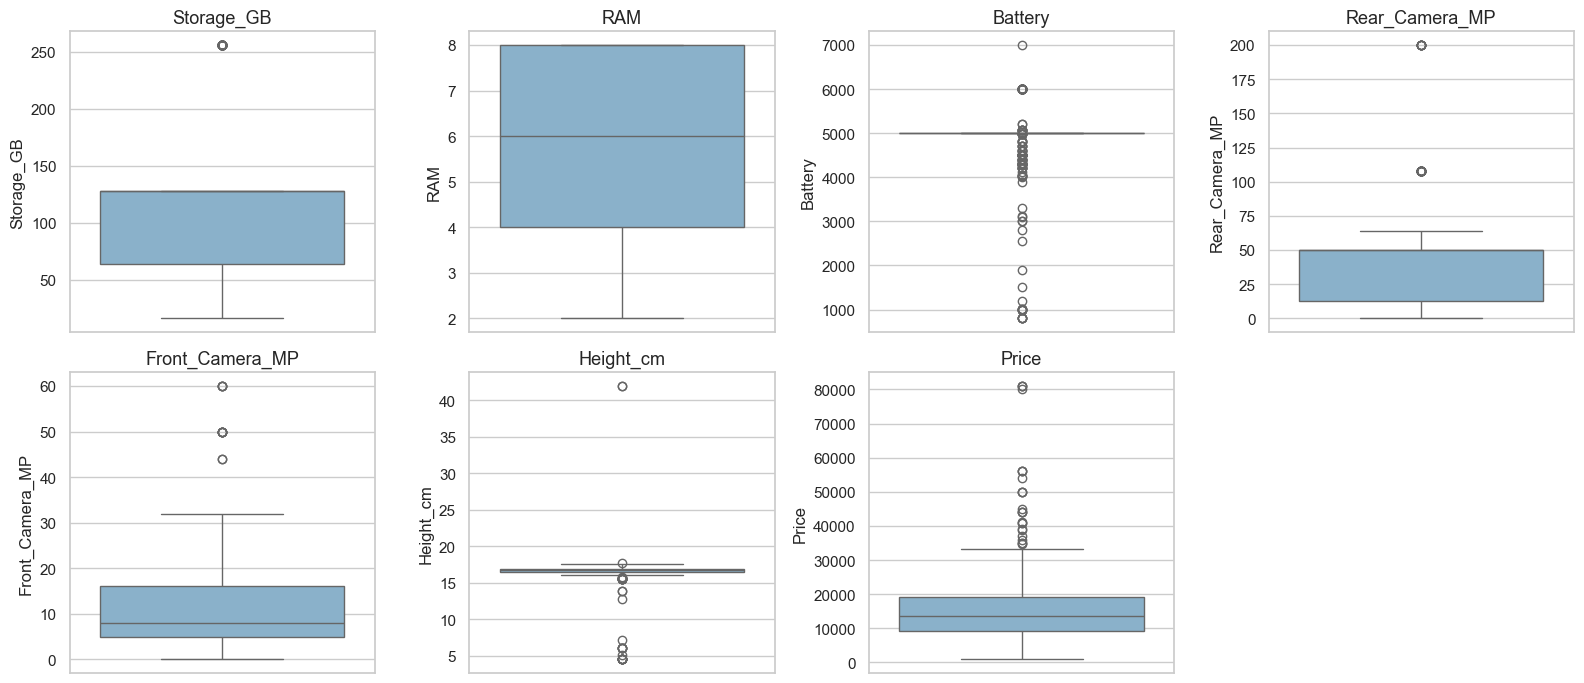

In [23]:

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.ravel(), num_cols):
    sns.boxplot(y=df[c], ax=ax, color="#7fb3d5"); ax.set_title(c)
axes.ravel()[-1].axis("off")
plt.tight_layout(); plt.show()


In [24]:

# Height_cm: values > 25 cm are impossible for a phone (data-entry error, e.g. 41.94 for a Moto G62).
bad_height = df["Height_cm"] > 25
print("Rows with impossible height:", bad_height.sum())
display(df.loc[bad_height, ["Model", "Height_cm", "Price"]])

# Replace with the median height of the same model / same brand (fallback: overall median of 'normal' phones)
df.loc[bad_height, "Height_cm"] = np.nan
df["Height_cm"] = df["Height_cm"].fillna(df.groupby("Model")["Height_cm"].transform("median"))
df["Height_cm"] = df["Height_cm"].fillna(df.groupby("Brand")["Height_cm"].transform("median"))
print("Remaining NaN in Height_cm:", df["Height_cm"].isna().sum())
print("Fixed values:", df.loc[bad_height, "Height_cm"].unique())


Rows with impossible height: 2


,Model,Height_cm,Price
75,motorola g62 5g,41.94,16499
88,motorola g62 5g,41.94,16499


Remaining NaN in Height_cm: 0
Fixed values: [16.64]


In [25]:

# Low battery / small height / 0MP cameras belong to basic *feature phones* (Micromax, Itel, Redmi 'mini' ...).
# They are genuine low-price products, so we KEEP them – removing them would hide the low end of the market.
feature_phones = df[(df["Battery"] < 2000) | (df["Rear_Camera_MP"] == 0)]
print("Feature-phone-like rows kept:", len(feature_phones))
feature_phones[["Model", "Battery", "Rear_Camera_MP", "Height_cm", "Price"]].head(8)


Feature-phone-like rows kept: 16


,Model,Battery,Rear_Camera_MP,Height_cm,Price
98,micromax in 2c,800,0.0,4.50,1449
108,micromax 2,1900,2.0,7.11,1849
116,micromax,1000,0.0,4.50,1422
118,micromax 1,800,0.0,4.50,1299
133,micromax 3,1020,2.0,6.10,2615
152,micromax 3,800,2.0,5.08,2490
155,micromax 2,800,0.0,4.50,1299
156,micromax 3,1020,2.0,6.10,2499


In [26]:

# Duplicates: identical in every column INCLUDING colour = genuine duplicate listings -> drop
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Dropped {before - len(df)} exact duplicate rows -> {len(df)} rows remain")

# Price is strongly right-skewed (a few premium phones). We keep those rows (they are real)
# and instead model log(Price) – see next section.
print("Price skewness:", round(df['Price'].skew(), 2), "| log-price skewness:", round(np.log1p(df['Price']).skew(), 2))


Dropped 10 exact duplicate rows -> 531 rows remain
Price skewness: 2.42 | log-price skewness: -0.6


In [27]:

df["Log_Price"] = np.log1p(df["Price"])
print("Missing values after cleaning:", df.isna().sum().sum())
df.head()


Missing values after cleaning: 0


,Model,Colour,Storage_GB,RAM,Battery,AI_Lens,Height_cm,Processor,Price,Brand,Rear_Camera_MP,Front_Camera_MP,Processor_Family,Is_5G,Colour_Family,Log_Price
0,infinix smart 7,Night Black,64,4,6000,1,16.76,Unisoc Spreadtrum SC9863A1,7299,infinix,13.0,5.0,Unisoc,0,Black,8.895630
1,infinix smart 7,Azure Blue,64,4,6000,1,16.76,Unisoc Spreadtrum SC9863A1,7299,infinix,13.0,5.0,Unisoc,0,Blue,8.895630
2,motorola g32,Mineral Gray,128,8,5000,0,16.64,Qualcomm Snapdragon 680,11999,motorola,50.0,16.0,Qualcomm Snapdragon,0,Gray,9.392662
3,poco c50,Royal Blue,32,2,5000,0,16.56,Mediatek Helio A22,5649,poco,8.0,5.0,MediaTek,0,Blue,8.639411
4,infinix hot 30i,Marigold,128,8,5000,1,16.76,G37,8999,infinix,50.0,5.0,MediaTek,0,Gold,9.104980


## 4. Exploratory Visualizations

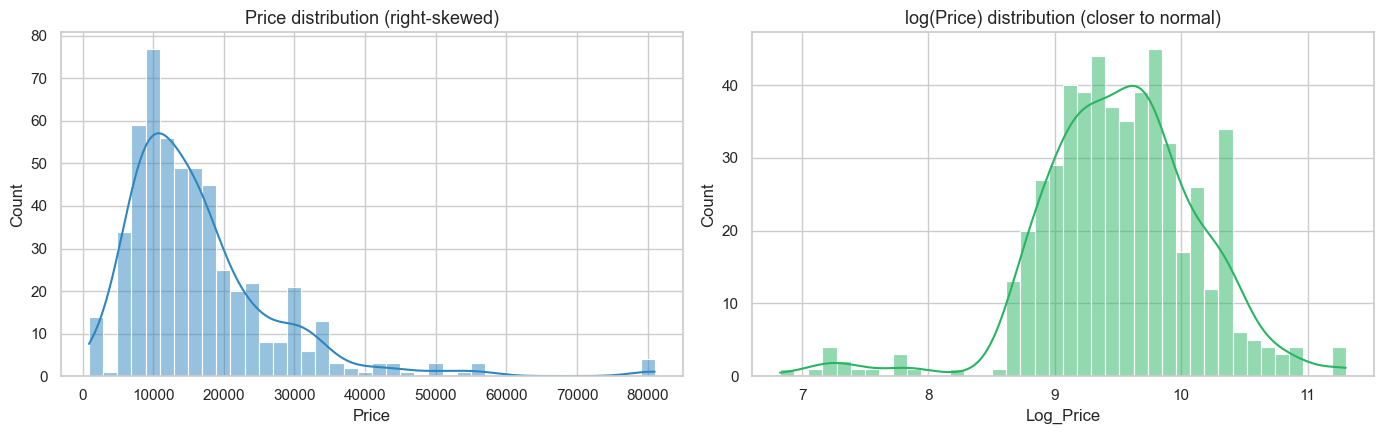

In [28]:

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(df["Price"], bins=40, kde=True, ax=axes[0], color="#2e86c1"); axes[0].set_title("Price distribution (right-skewed)")
sns.histplot(df["Log_Price"], bins=40, kde=True, ax=axes[1], color="#28b463"); axes[1].set_title("log(Price) distribution (closer to normal)")
plt.tight_layout(); plt.show()


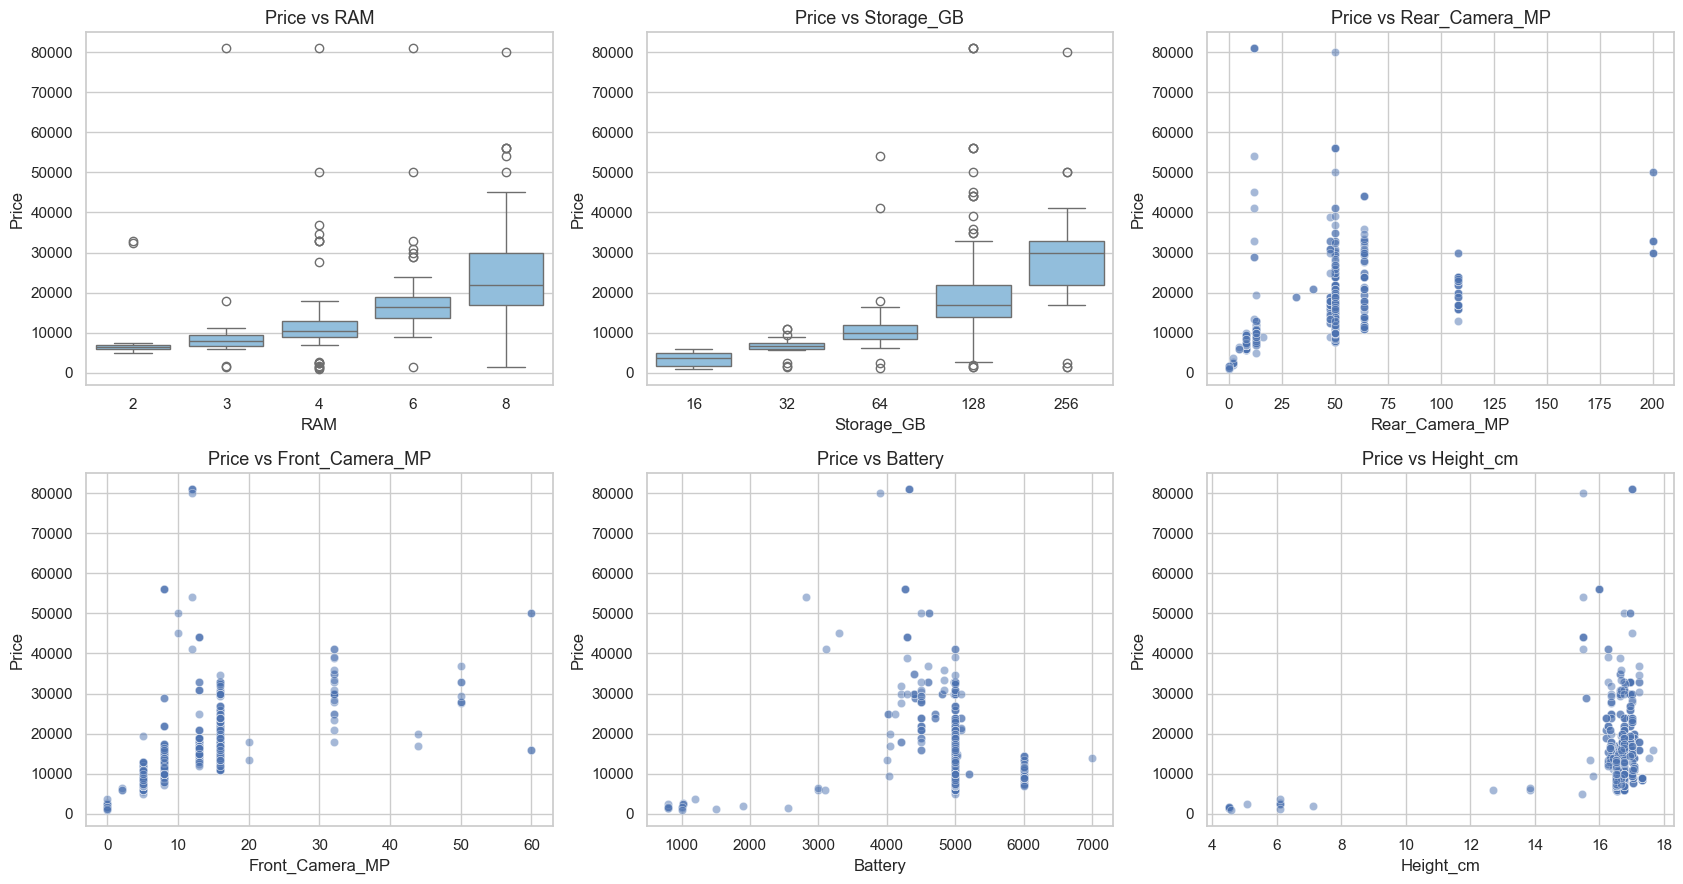

In [29]:

fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, c in zip(axes.ravel(), ["RAM", "Storage_GB", "Rear_Camera_MP", "Front_Camera_MP", "Battery", "Height_cm"]):
    if df[c].nunique() <= 8:
        sns.boxplot(data=df, x=c, y="Price", ax=ax, color="#85c1e9")
    else:
        sns.scatterplot(data=df, x=c, y="Price", alpha=.5, ax=ax)
    ax.set_title(f"Price vs {c}")
plt.tight_layout(); plt.show()


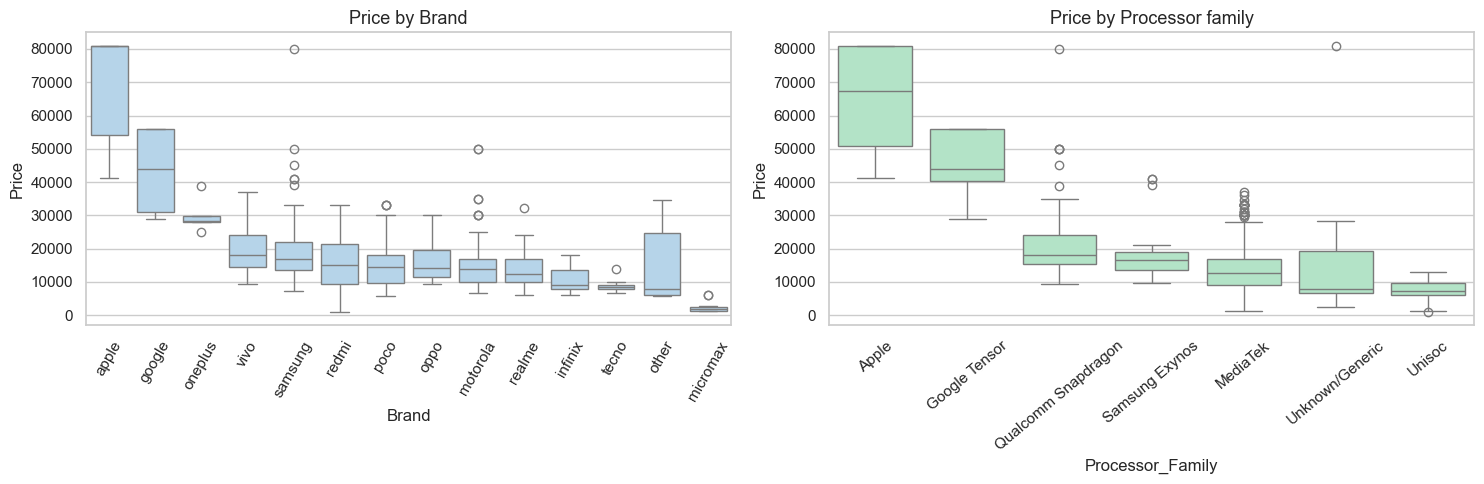

In [30]:

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
order = df.groupby("Brand")["Price"].median().sort_values(ascending=False).index
sns.boxplot(data=df, x="Brand", y="Price", order=order, ax=axes[0], color="#aed6f1")
axes[0].set_title("Price by Brand"); axes[0].tick_params(axis="x", rotation=60)

order = df.groupby("Processor_Family")["Price"].median().sort_values(ascending=False).index
sns.boxplot(data=df, x="Processor_Family", y="Price", order=order, ax=axes[1], color="#abebc6")
axes[1].set_title("Price by Processor family"); axes[1].tick_params(axis="x", rotation=40)
plt.tight_layout(); plt.show()


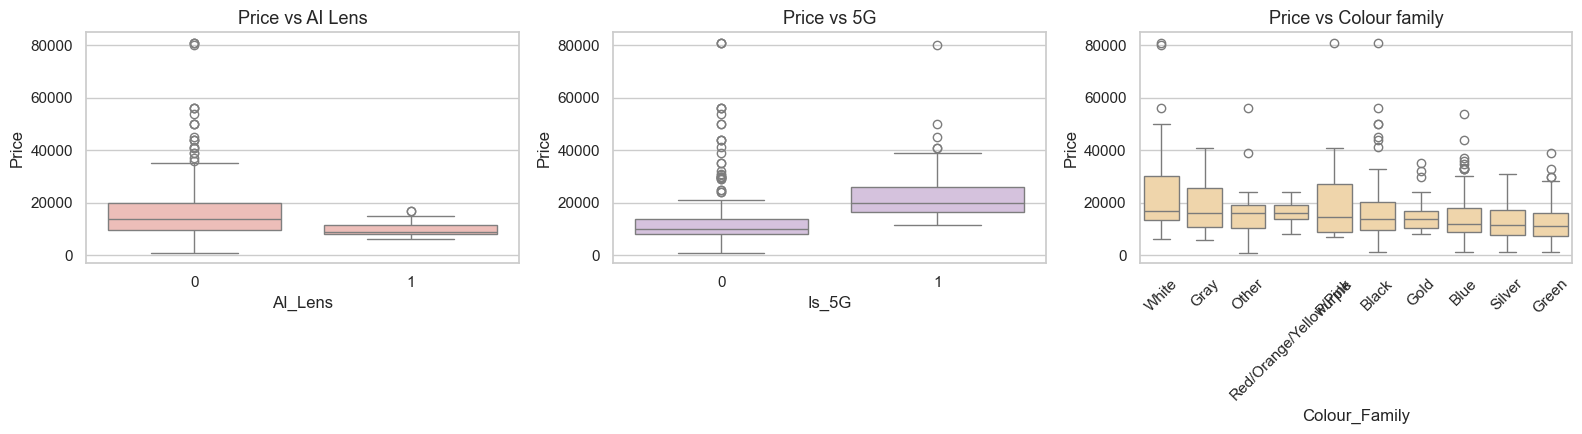

In [31]:

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.boxplot(data=df, x="AI_Lens", y="Price", ax=axes[0], color="#f5b7b1"); axes[0].set_title("Price vs AI Lens")
sns.boxplot(data=df, x="Is_5G", y="Price", ax=axes[1], color="#d7bde2"); axes[1].set_title("Price vs 5G")
order = df.groupby("Colour_Family")["Price"].median().sort_values(ascending=False).index
sns.boxplot(data=df, x="Colour_Family", y="Price", order=order, ax=axes[2], color="#fad7a0")
axes[2].set_title("Price vs Colour family"); axes[2].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()



## 5. Feature Extraction
We use **five complementary techniques** to find the features that matter most. Using several methods avoids relying on one method's blind spots (for example, correlation only sees *linear* relationships).

| # | Technique | What it tells us |
|---|-----------|------------------|
| 1 | Pearson & Spearman correlation | linear / monotonic relation with price |
| 2 | Mutual information | any (also non-linear) dependence on price |
| 3 | ANOVA / F-test (`f_regression`) | statistical significance of each feature |
| 4 | PCA | how much the numeric features overlap (dimensionality reduction) |
| 5 | Random Forest importance | contribution to predictions (done in Section 9) |

### 5.1 Encode categorical variables (one-hot)
`Model` and `Colour` have 187 and 275 unique values, so we encode their **grouped versions** – `Brand` (from Model) and `Colour_Family` (from Colour) – together with `Processor_Family`. This gives a compact one-hot matrix instead of ~460 mostly-empty columns.


In [32]:

numeric_features = ["Storage_GB", "RAM", "Battery", "Rear_Camera_MP", "Front_Camera_MP", "Height_cm", "AI_Lens", "Is_5G"]
categorical_features = ["Brand", "Processor_Family", "Colour_Family"]
target = "Price"

df_encoded = pd.get_dummies(df[numeric_features + categorical_features], columns=categorical_features, dtype=int)
print("Encoded feature matrix:", df_encoded.shape)
df_encoded.head()


Encoded feature matrix: (531, 39)


,Storage_GB,RAM,Battery,Rear_Camera_MP,Front_Camera_MP,Height_cm,AI_Lens,Is_5G,Brand_apple,Brand_google,Brand_infinix,Brand_micromax,Brand_motorola,Brand_oneplus,Brand_oppo,Brand_other,Brand_poco,Brand_realme,Brand_redmi,Brand_samsung,Brand_tecno,Brand_vivo,Processor_Family_Apple,Processor_Family_Google Tensor,Processor_Family_MediaTek,Processor_Family_Qualcomm Snapdragon,Processor_Family_Samsung Exynos,Processor_Family_Unisoc,Processor_Family_Unknown/Generic,Colour_Family_Black,Colour_Family_Blue,Colour_Family_Gold,Colour_Family_Gray,Colour_Family_Green,Colour_Family_Other,Colour_Family_Purple,Colour_Family_Red/Orange/Yellow/Pink,Colour_Family_Silver,Colour_Family_White
0,64,4,6000,13.0,5.0,16.76,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0
1,64,4,6000,13.0,5.0,16.76,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0
2,128,8,5000,50.0,16.0,16.64,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0
3,32,2,5000,8.0,5.0,16.56,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0,0,0,0
4,128,8,5000,50.0,5.0,16.76,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0


### 5.2 Correlation analysis

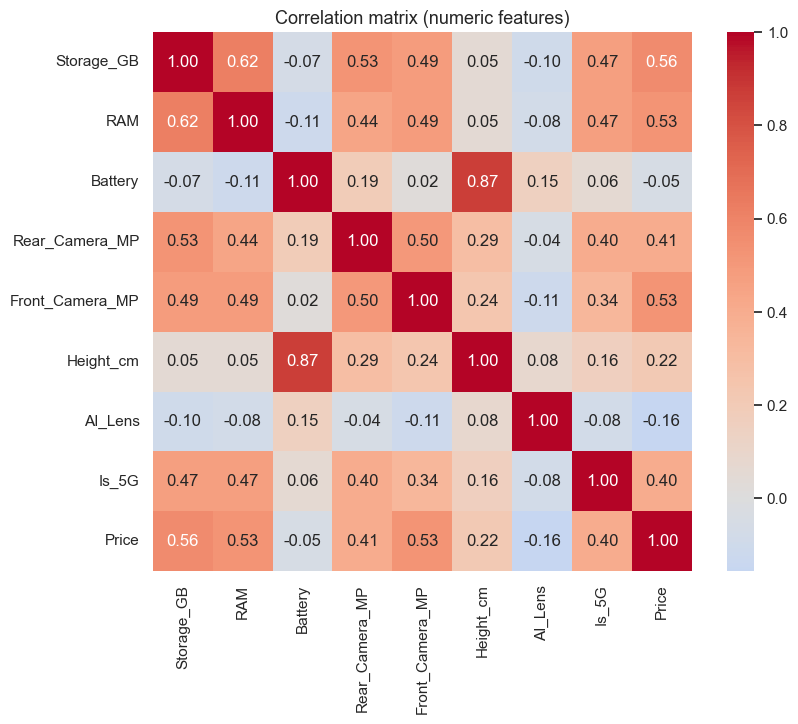

In [33]:

corr = df[numeric_features + [target]].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation matrix (numeric features)"); plt.show()


,Pearson,Spearman,abs_Spearman
Front_Camera_MP,0.529,0.808,0.808
Storage_GB,0.564,0.767,0.767
RAM,0.529,0.732,0.732
Is_5G,0.400,0.623,0.623
Rear_Camera_MP,0.407,0.622,0.622
Battery,-0.046,-0.310,0.310
Height_cm,0.216,0.209,0.209
AI_Lens,-0.156,-0.205,0.205


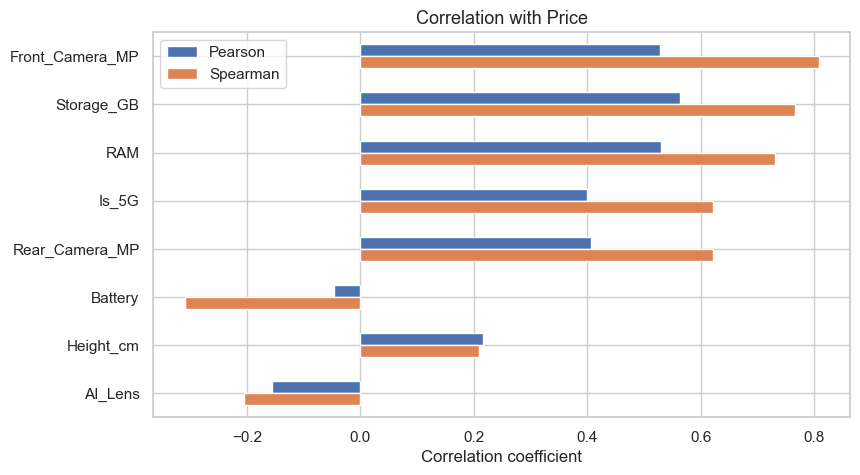

In [38]:

corr_table = pd.DataFrame({
    "Pearson":  [df[c].corr(df[target], method="pearson")  for c in numeric_features],
    "Spearman": [df[c].corr(df[target], method="spearman") for c in numeric_features],
}, index=numeric_features)
corr_table["abs_Spearman"] = corr_table["Spearman"].abs()
corr_table = corr_table.sort_values("abs_Spearman", ascending=False)
display(corr_table.round(3))

corr_table[["Pearson", "Spearman"]].plot(kind="barh", figsize=(9, 5), title="Correlation with Price").invert_yaxis()
plt.xlabel("Correlation coefficient"); plt.show()


### 5.3 Mutual information and F-test (all encoded features)

,Mutual_Info,F_score,p_value
Front_Camera_MP,0.7962,320.2308,0.0000
Rear_Camera_MP,0.7086,238.5984,0.0000
RAM,0.6741,296.3352,0.0000
Storage_GB,0.6708,273.3613,0.0000
Height_cm,0.6422,236.5166,0.0000
Battery,0.4316,46.6971,0.0000
Is_5G,0.3246,190.8604,0.0000
Processor_Family_Qualcomm Snapdragon,0.1810,57.1536,0.0000
Processor_Family_Unisoc,0.1687,131.0370,0.0000
Processor_Family_MediaTek,0.1655,3.0433,0.0817


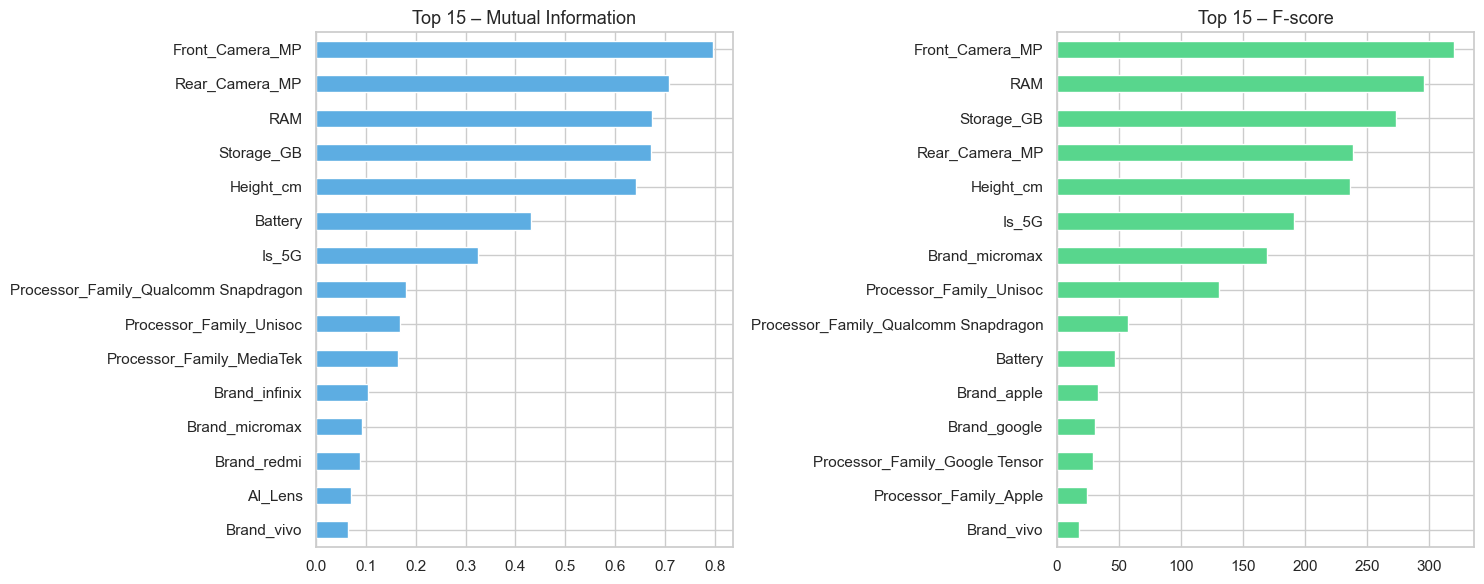

In [39]:

X_enc, y = df_encoded, df["Log_Price"]

mi = mutual_info_regression(X_enc, y, random_state=RANDOM_STATE)
f_stat, p_val = f_regression(X_enc, y)

selection = pd.DataFrame({"Mutual_Info": mi, "F_score": f_stat, "p_value": p_val}, index=X_enc.columns)
selection = selection.sort_values("Mutual_Info", ascending=False)
display(selection.head(15).round(4))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
selection["Mutual_Info"].head(15).sort_values().plot(kind="barh", ax=axes[0], color="#5dade2", title="Top 15 – Mutual Information")
selection["F_score"].sort_values(ascending=False).head(15).sort_values().plot(kind="barh", ax=axes[1], color="#58d68d", title="Top 15 – F-score")
plt.tight_layout(); plt.show()


### 5.4 Dimensionality reduction with PCA (numeric features)

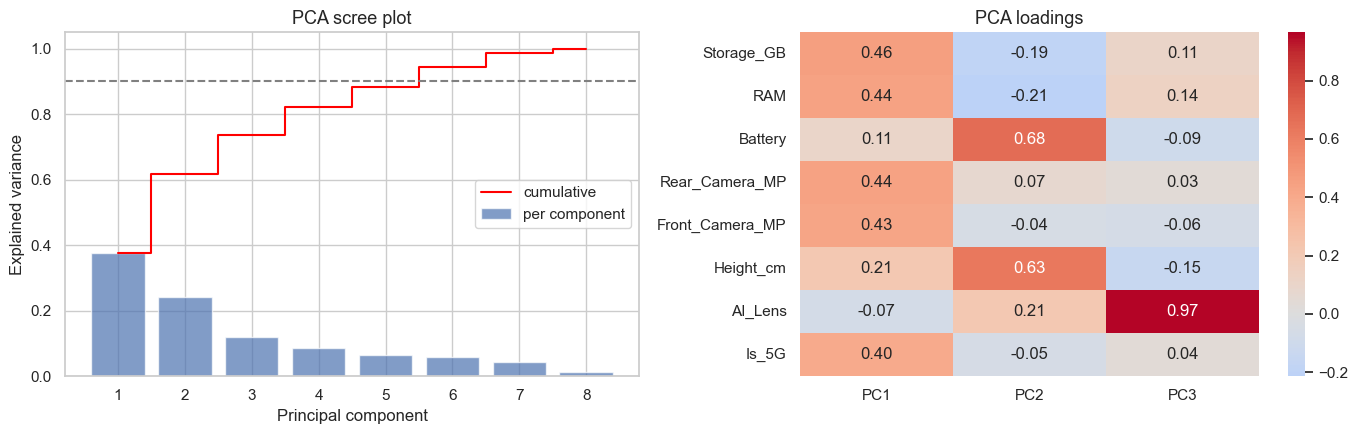

Components needed for 90% variance: 6 of 8
Correlation of PC1 with Price (Spearman): 0.889


In [40]:

scaled = StandardScaler().fit_transform(df[numeric_features])
pca = PCA().fit(scaled)

cum_var = np.cumsum(pca.explained_variance_ratio_)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].bar(range(1, len(cum_var) + 1), pca.explained_variance_ratio_, alpha=.7, label="per component")
axes[0].step(range(1, len(cum_var) + 1), cum_var, where="mid", color="red", label="cumulative")
axes[0].axhline(.9, ls="--", color="gray"); axes[0].set_xlabel("Principal component"); axes[0].set_ylabel("Explained variance")
axes[0].set_title("PCA scree plot"); axes[0].legend()

loadings = pd.DataFrame(pca.components_[:3].T, index=numeric_features, columns=["PC1", "PC2", "PC3"])
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[1]); axes[1].set_title("PCA loadings")
plt.tight_layout(); plt.show()

print(f"Components needed for 90% variance: {np.argmax(cum_var >= .9) + 1} of {len(numeric_features)}")
pc1 = pd.Series(pca.transform(scaled)[:, 0])
print("Correlation of PC1 with Price (Spearman):", round(pc1.corr(df['Price'], method='spearman'), 3))



### 5.5 Combined ranking from the statistical methods
We convert each score to a rank (1 = most important) and average them, so the final list is not driven by a single method.


In [41]:

rank_df = pd.DataFrame(index=X_enc.columns)
rank_df["MI_rank"] = selection["Mutual_Info"].rank(ascending=False)
rank_df["F_rank"]  = selection["F_score"].rank(ascending=False)
rank_df["Spearman_rank"] = (X_enc.apply(lambda s: abs(s.corr(df["Price"], method="spearman")))).rank(ascending=False)
rank_df["Mean_rank"] = rank_df.mean(axis=1)
stat_ranking = rank_df.sort_values("Mean_rank")
display(stat_ranking.head(12).round(1))


,MI_rank,F_rank,Spearman_rank,Mean_rank
Front_Camera_MP,1.0,1.0,1.0,1.0
RAM,3.0,2.0,3.0,2.7
Storage_GB,4.0,3.0,2.0,3.0
Rear_Camera_MP,2.0,4.0,5.0,3.7
Is_5G,7.0,6.0,4.0,5.7
Height_cm,5.0,5.0,12.0,7.3
Processor_Family_Unisoc,9.0,8.0,6.0,7.7
Battery,6.0,10.0,8.0,8.0
Processor_Family_Qualcomm Snapdragon,8.0,9.0,7.0,8.0
Brand_micromax,12.0,7.0,9.0,9.3



## 6. Model Building

### 6.1 Train / test split
The same phone is listed once **per colour** with identical specs and price. A plain random split would put colour variants of the same phone in both train and test sets and *leak* the answer, making the model look better than it really is.
We therefore use a **grouped split by `Model`**: every model appears entirely in train *or* entirely in test, which mimics predicting the price of a phone the model has never seen. We also use the `log(Price)` as the target (it is far less skewed) and convert predictions back to rupees for evaluation.


In [42]:

features = numeric_features + categorical_features
X = df[features]
y_log = df["Log_Price"]
y = df["Price"]
groups = df["Model"]

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(gss.split(X, y_log, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train_log, y_test_log = y_log.iloc[train_idx], y_log.iloc[test_idx]
y_test = y.iloc[test_idx]
groups_train = groups.iloc[train_idx]

print(f"Train: {X_train.shape[0]} rows ({groups.iloc[train_idx].nunique()} models)")
print(f"Test : {X_test.shape[0]} rows ({groups.iloc[test_idx].nunique()} models)")
print("Models shared between train and test:", len(set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])))


Train: 430 rows (144 models)
Test : 101 rows (37 models)
Models shared between train and test: 0


### 6.2 Pre-processing pipeline and candidate models

In [43]:

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
])

models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression":  Ridge(alpha=1.0),
    "Decision Tree":     DecisionTreeRegressor(max_depth=8, min_samples_leaf=3, random_state=RANDOM_STATE),
    "Random Forest":     RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=300, learning_rate=0.05, max_depth=3, random_state=RANDOM_STATE),
}

pipelines = {name: Pipeline([("prep", preprocessor), ("model", m)]) for name, m in models.items()}
for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train_log)
print("All", len(pipelines), "models trained.")


All 5 models trained.



## 7. Model Evaluation
Metrics (computed on the **original price scale in ₹** for the held-out test set):

- **MAE** – average absolute error in rupees
- **RMSE** – like MAE but penalises large errors more
- **R²** – share of price variance explained
- **MAPE** – average percentage error


In [44]:

def evaluate(pipe, X_te, y_te_price):
    pred = np.expm1(pipe.predict(X_te))
    return {
        "MAE (₹)":  mean_absolute_error(y_te_price, pred),
        "RMSE (₹)": np.sqrt(mean_squared_error(y_te_price, pred)),
        "R²":       r2_score(y_te_price, pred),
        "MAPE (%)": np.mean(np.abs((y_te_price - pred) / y_te_price)) * 100,
    }

results = pd.DataFrame({n: evaluate(p, X_test, y_test) for n, p in pipelines.items()}).T

# 5-fold grouped cross-validation (R² on log-price) for a more stable comparison
gkf = GroupKFold(n_splits=5)
results["CV R² (log price)"] = [
    cross_val_score(p, X_train, y_train_log, groups=groups_train, cv=gkf, scoring="r2").mean()
    for p in pipelines.values()
]
results = results.sort_values("RMSE (₹)")
results.round(3)


,MAE (₹),RMSE (₹),R²,MAPE (%),CV R² (log price)
Linear Regression,2276.661,4011.371,0.817,12.466,0.853
Ridge Regression,2330.949,4106.967,0.808,12.732,0.852
Gradient Boosting,2950.003,5399.773,0.668,14.814,0.857
Random Forest,3606.810,5854.991,0.610,18.437,0.847
Decision Tree,4368.837,7406.206,0.376,21.335,0.792


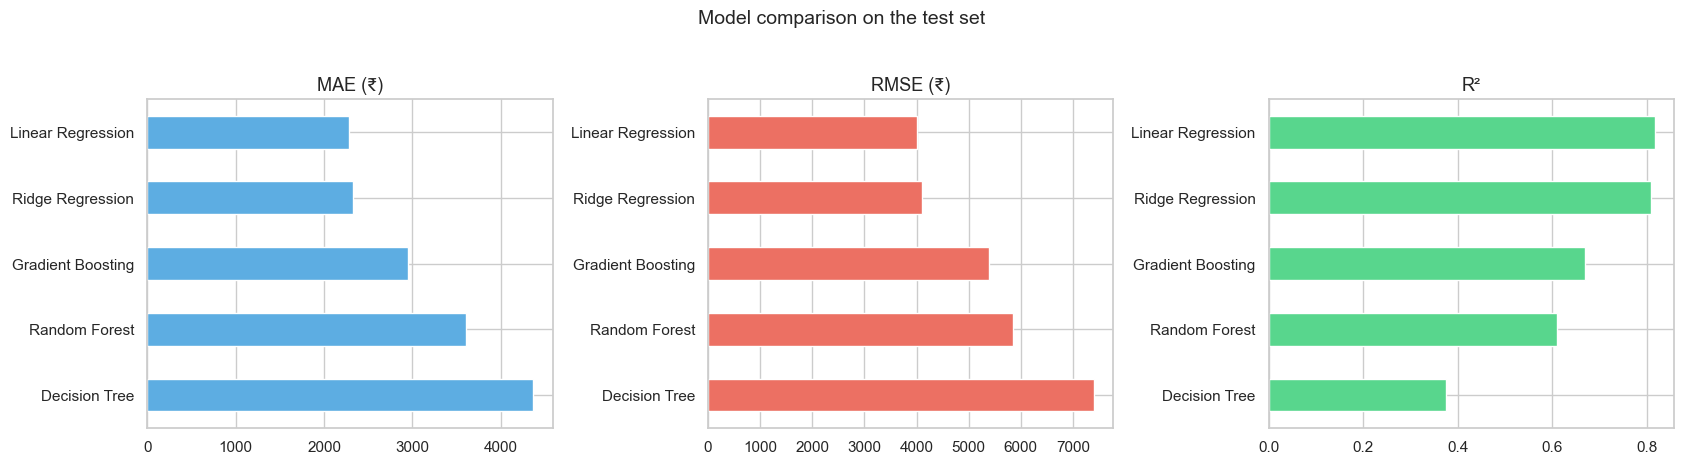

Best model on test RMSE: Linear Regression


In [45]:

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, metric, col in zip(axes, ["MAE (₹)", "RMSE (₹)", "R²"], ["#5dade2", "#ec7063", "#58d68d"]):
    results[metric].sort_values(ascending=(metric == "R²")).plot(kind="barh", ax=ax, color=col)
    ax.set_title(metric)
plt.suptitle("Model comparison on the test set", y=1.03, fontsize=14); plt.tight_layout(); plt.show()

best_name = results.index[0]
print("Best model on test RMSE:", best_name)


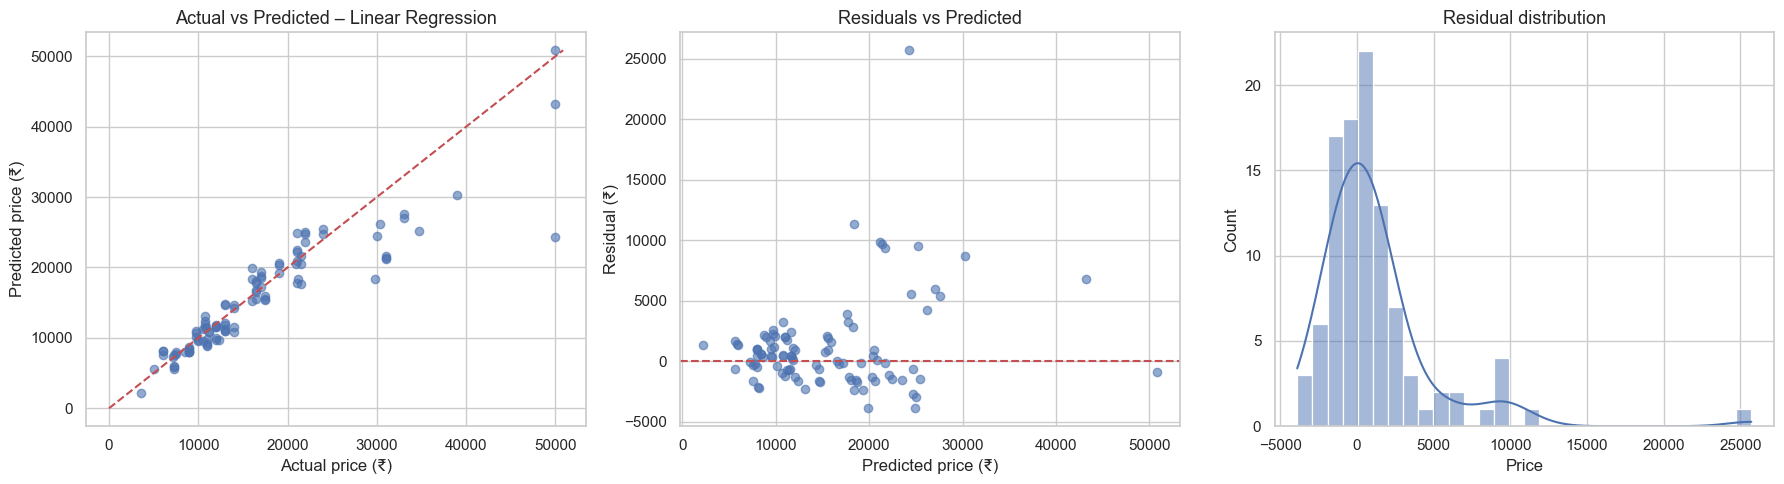

In [68]:

# Actual vs predicted + residuals for the best baseline model
best_pipe = pipelines[best_name]
pred = np.expm1(best_pipe.predict(X_test))
resid = y_test - pred

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].scatter(y_test, pred, alpha=.6)
lims = [0, max(y_test.max(), pred.max())]
axes[0].plot(lims, lims, "r--"); axes[0].set_xlabel("Actual price (₹)"); axes[0].set_ylabel("Predicted price (₹)")
axes[0].set_title(f"Actual vs Predicted – {best_name}")

axes[1].scatter(pred, resid, alpha=.6); axes[1].axhline(0, color="r", ls="--")
axes[1].set_xlabel("Predicted price (₹)"); axes[1].set_ylabel("Residual (₹)"); axes[1].set_title("Residuals vs Predicted")

sns.histplot(resid, bins=30, kde=True, ax=axes[2]); axes[2].set_title("Residual distribution")
plt.tight_layout(); plt.show()



## 8. Hyperparameter Tuning
The two tree-ensemble models are the strongest candidates, so we tune both with a grouped 5-fold cross-validated grid search (grouped by `Model` to avoid leakage) and keep the better one.


In [65]:

param_grids = {
    "Random Forest": {
        "model__n_estimators": [200, 400],
        "model__max_depth": [None, 10, 20],
        "model__min_samples_leaf": [1, 2, 4],
        "model__max_features": ["sqrt", 0.6, 1.0],
    },
    "Gradient Boosting": {
        "model__n_estimators": [200, 400],
        "model__learning_rate": [0.03, 0.05, 0.1],
        "model__max_depth": [2, 3, 4],
        "model__subsample": [0.8, 1.0],
    },
}

searches = {}
for name, grid in param_grids.items():
    gs = GridSearchCV(pipelines[name], grid, cv=GroupKFold(n_splits=5),
                      scoring="neg_mean_absolute_error", n_jobs=-1)
    gs.fit(X_train, y_train_log, groups=groups_train)
    searches[name] = gs
    print(f"{name:18s} best CV MAE (log) = {-gs.best_score_:.4f} | params = {gs.best_params_}")


Random Forest      best CV MAE (log) = 0.1691 | params = {'model__max_depth': None, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 1, 'model__n_estimators': 400}
Gradient Boosting  best CV MAE (log) = 0.1518 | params = {'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__n_estimators': 200, 'model__subsample': 1.0}


In [66]:

tuned = pd.DataFrame({f"{n} (tuned)": evaluate(gs.best_estimator_, X_test, y_test) for n, gs in searches.items()}).T
comparison = pd.concat([results.drop(columns="CV R² (log price)"), tuned]).sort_values("RMSE (₹)")
display(comparison.round(3))

# every fitted candidate in one dictionary
all_fitted = {**pipelines, **{f"{n} (tuned)": gs.best_estimator_ for n, gs in searches.items()}}

final_name  = comparison["RMSE (₹)"].idxmin()          # best overall accuracy on unseen phone models
final_model = all_fitted[final_name]

# best *tree ensemble* – used below for impurity importance and partial dependence
tree_name  = tuned["RMSE (₹)"].idxmin()
tree_model = all_fitted[tree_name]
print(f"\nFinal model (lowest test RMSE): {final_name}")
print(f"Best tree ensemble            : {tree_name}")


,MAE (₹),RMSE (₹),R²,MAPE (%)
Linear Regression,2276.661,4011.371,0.817,12.466
Ridge Regression,2330.949,4106.967,0.808,12.732
Gradient Boosting,2950.003,5399.773,0.668,14.814
Gradient Boosting (tuned),3075.828,5405.973,0.668,15.274
Random Forest (tuned),3163.670,5797.547,0.618,15.027
Random Forest,3606.810,5854.991,0.610,18.437
Decision Tree,4368.837,7406.206,0.376,21.335



Final model (lowest test RMSE): Linear Regression
Best tree ensemble            : Gradient Boosting (tuned)


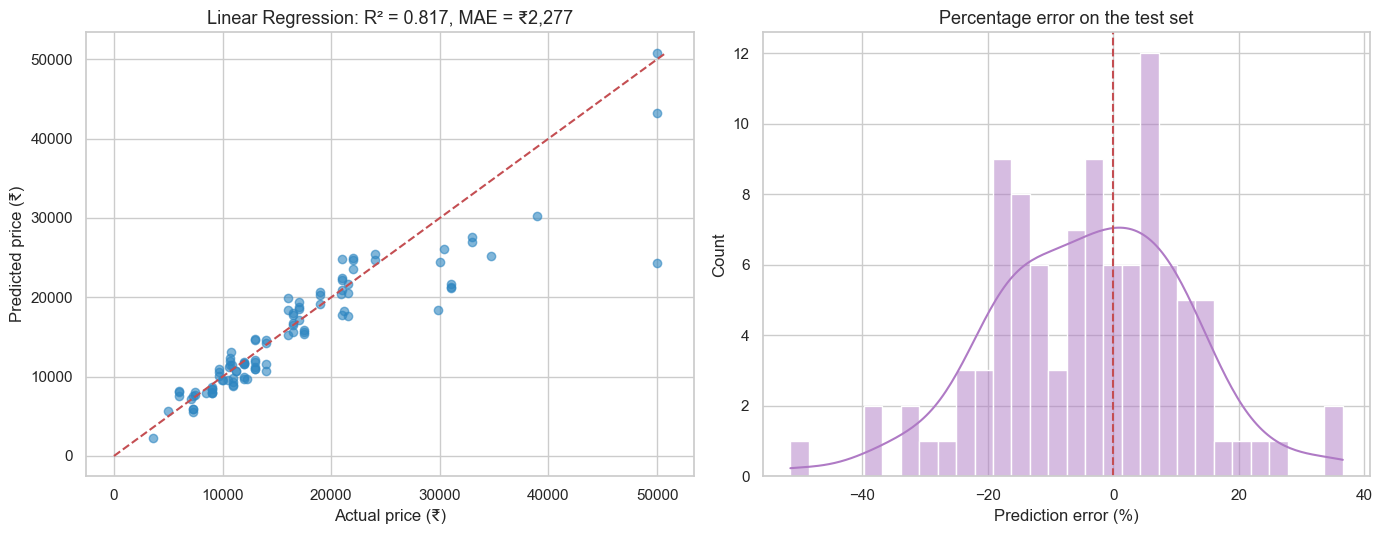

In [67]:

# Final-model diagnostics
pred_final = np.expm1(final_model.predict(X_test))
m = evaluate(final_model, X_test, y_test)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
axes[0].scatter(y_test, pred_final, alpha=.6, color="#2e86c1")
lims = [0, max(y_test.max(), pred_final.max())]
axes[0].plot(lims, lims, "r--"); axes[0].set_xlabel("Actual price (₹)"); axes[0].set_ylabel("Predicted price (₹)")
axes[0].set_title(f"{final_name}: R² = {m['R²']:.3f}, MAE = ₹{m['MAE (₹)']:,.0f}")

err_pct = (pred_final - y_test) / y_test * 100
sns.histplot(err_pct, bins=30, kde=True, ax=axes[1], color="#af7ac5")
axes[1].axvline(0, color="r", ls="--"); axes[1].set_xlabel("Prediction error (%)"); axes[1].set_title("Percentage error on the test set")
plt.tight_layout(); plt.show()



> **Why does a simple linear model win?** After taking `log(Price)`, phone prices are close to an *additive* function of RAM, storage, cameras, 5G, etc. With only ~430 training rows (144 distinct phone models) the flexible tree ensembles have little extra structure to learn and tend to over-fit, whereas the linear model generalises well to phone models it has never seen. The grouped cross-validation scores in Section 7 tell the same story – the models are close in CV, but linear models are the most stable on new models. We keep the tree ensembles because they capture non-linear effects and give a second, independent view of feature importance.



## 9. Feature Importance Analysis
We confirm the features found in Section 5 using the trained models, with two views:

1. **Impurity-based importance** (built into the best tree ensemble, summed per original feature)
2. **Permutation importance** on the held-out test set – shuffle one original feature at a time and measure how much the error grows. It is model-agnostic, so we compute it for **both** the final model and the best tree ensemble and check that they agree.


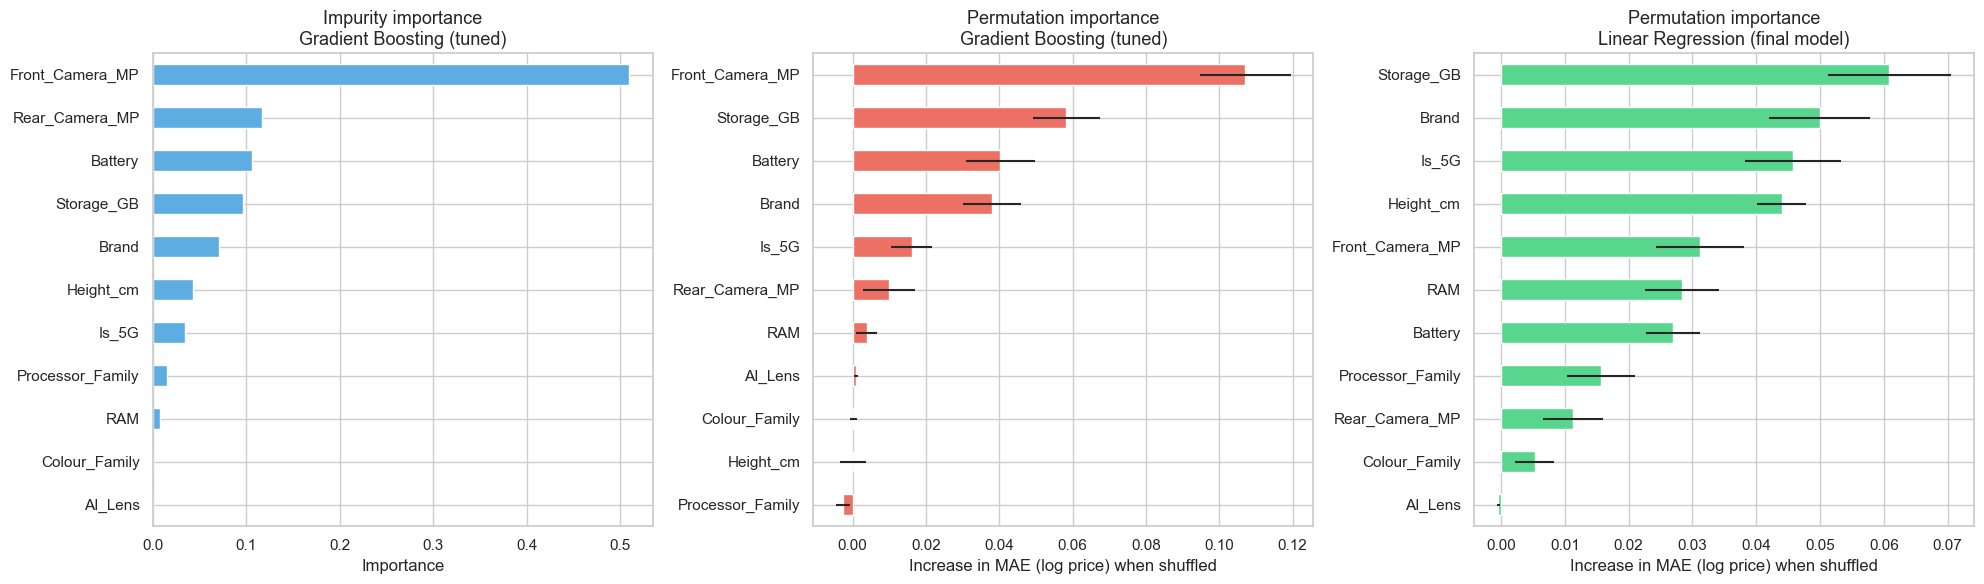

In [59]:

# 1) impurity-based importance of the tree ensemble, aggregated back to the original features
est = tree_model.named_steps["model"]
names = tree_model.named_steps["prep"].get_feature_names_out()
imp = pd.Series(est.feature_importances_, index=names)

def original_feature(n):
    n = n.split("__", 1)[1]
    for c in categorical_features:
        if n.startswith(c + "_"):
            return c
    return n

imp_grouped = imp.groupby(imp.index.map(original_feature)).sum().sort_values(ascending=False)

# 2) permutation importance on the test set (raw columns -> one score per original feature)
def perm_importance(model):
    p = permutation_importance(model, X_test, y_test_log, n_repeats=30, random_state=RANDOM_STATE,
                               scoring="neg_mean_absolute_error", n_jobs=-1)
    return pd.Series(p.importances_mean, index=X_test.columns), pd.Series(p.importances_std, index=X_test.columns)

perm_final, perm_final_std = perm_importance(final_model)
perm_tree,  perm_tree_std  = perm_importance(tree_model)

order = perm_final.sort_values().index
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
imp_grouped.sort_values().plot(kind="barh", ax=axes[0], color="#5dade2")
axes[0].set_title(f"Impurity importance\n{tree_name}")
perm_tree[perm_tree.sort_values().index].plot(kind="barh", ax=axes[1], xerr=perm_tree_std[perm_tree.sort_values().index], color="#ec7063")
axes[1].set_title(f"Permutation importance\n{tree_name}")
perm_final[order].plot(kind="barh", ax=axes[2], xerr=perm_final_std[order], color="#58d68d")
axes[2].set_title(f"Permutation importance\n{final_name} (final model)")
for a in axes[1:]: a.set_xlabel("Increase in MAE (log price) when shuffled")
axes[0].set_xlabel("Importance")
plt.tight_layout(); plt.show()


In [60]:

# Do the model importances agree with the extraction phase?
stat_by_feature = {f: stat_ranking.loc[f, "Mean_rank"] for f in numeric_features}
for c in categorical_features:                                # best rank of any dummy of that feature
    stat_by_feature[c] = stat_ranking.loc[[i for i in stat_ranking.index if i.startswith(c + "_")], "Mean_rank"].min()

summary = pd.DataFrame({
    "Statistical rank (Sec. 5)":        pd.Series(stat_by_feature).rank(),
    "Permutation rank (final model)":   perm_final.rank(ascending=False),
    "Permutation rank (tree ensemble)": perm_tree.rank(ascending=False),
    "Impurity rank (tree ensemble)":    imp_grouped.rank(ascending=False),
}).astype(int)
summary["Average rank"] = summary.mean(axis=1)
summary = summary.sort_values("Average rank")
display(summary.round(1))

print("Spearman agreement  statistical vs final-model permutation :",
      round(stats.spearmanr(summary.iloc[:, 0], summary.iloc[:, 1])[0], 3))
print("Spearman agreement  final-model vs tree-ensemble permutation:",
      round(stats.spearmanr(summary.iloc[:, 1], summary.iloc[:, 2])[0], 3))


,Statistical rank (Sec. 5),Permutation rank (final model),Permutation rank (tree ensemble),Impurity rank (tree ensemble),Average rank
Front_Camera_MP,1,5,1,1,2.0
Storage_GB,3,1,2,4,2.5
Brand,9,2,4,5,5.0
Is_5G,5,3,5,7,5.0
Battery,8,7,3,3,5.2
Rear_Camera_MP,4,9,6,2,5.2
RAM,2,6,7,9,6.0
Height_cm,6,4,10,6,6.5
Processor_Family,7,8,11,8,8.5
AI_Lens,10,11,8,11,10.0


Spearman agreement  statistical vs final-model permutation : 0.445
Spearman agreement  final-model vs tree-ensemble permutation: 0.518


### How do the top features change the predicted price? (Partial dependence)

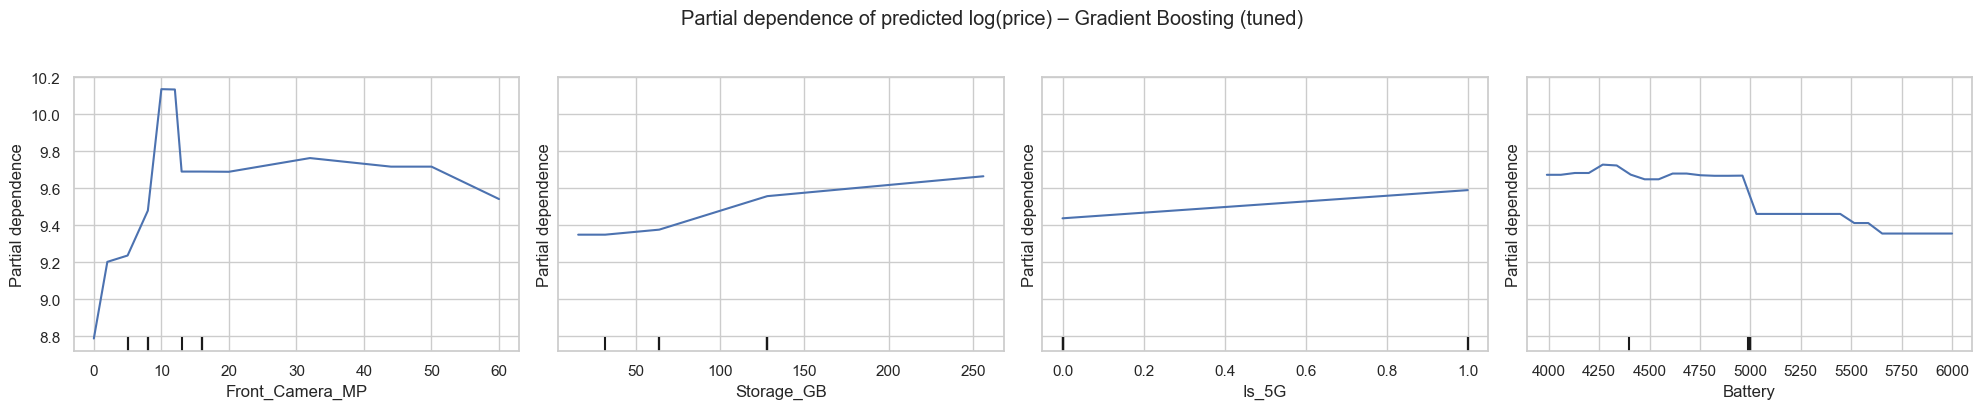

In [72]:

top_numeric = [f for f in summary.index if f in numeric_features][:4]
fig, ax = plt.subplots(1, len(top_numeric), figsize=(5 * len(top_numeric), 4), sharey=True)
PartialDependenceDisplay.from_estimator(tree_model, X_train, top_numeric, kind="average", ax=ax, grid_resolution=30)
fig.suptitle(f"Partial dependence of predicted log(price) – {tree_name}", y=1.02)
plt.tight_layout(); plt.show()


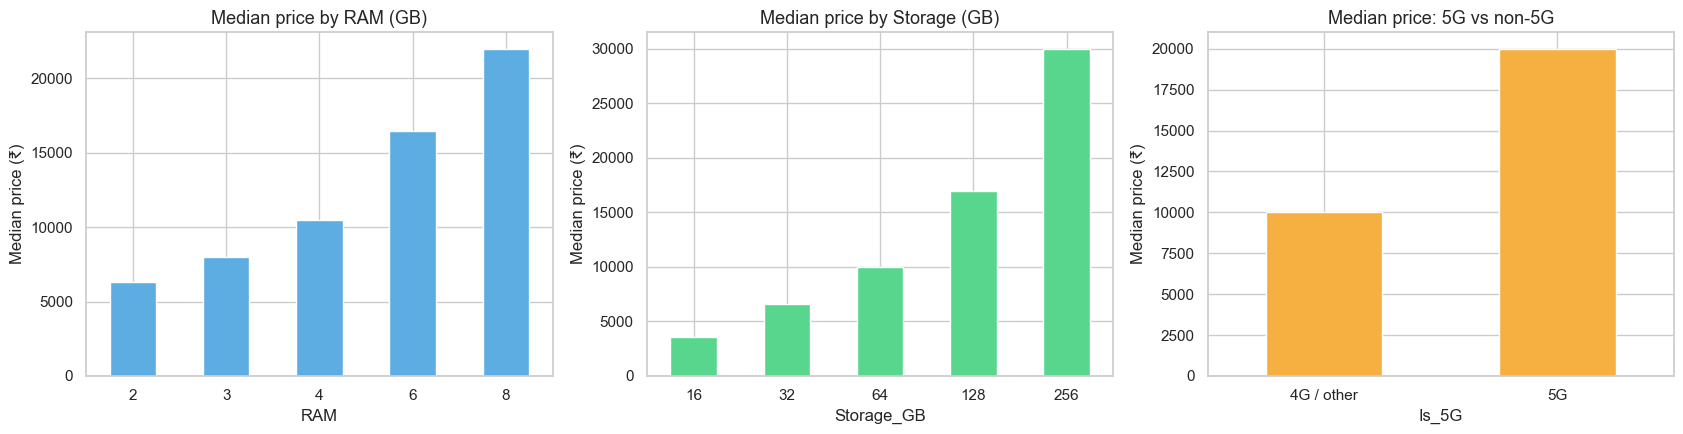

In [73]:

# Average price level per feature value (simple, business-friendly view)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
df.groupby("RAM")["Price"].median().plot(kind="bar", ax=axes[0], color="#5dade2", title="Median price by RAM (GB)")
df.groupby("Storage_GB")["Price"].median().plot(kind="bar", ax=axes[1], color="#58d68d", title="Median price by Storage (GB)")
df.groupby("Is_5G")["Price"].median().rename({0: "4G / other", 1: "5G"}).plot(kind="bar", ax=axes[2], color="#f5b041", title="Median price: 5G vs non-5G")
for a in axes: a.set_ylabel("Median price (₹)"); a.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()


### Save the final model (optional)

In [69]:

import joblib
joblib.dump(final_model, "mobile_price_model.joblib")

# Example: predict the price of a new phone
new_phone = pd.DataFrame([{
    "Storage_GB": 128, "RAM": 8, "Battery": 5000, "Rear_Camera_MP": 50, "Front_Camera_MP": 16,
    "Height_cm": 16.7, "AI_Lens": 0, "Is_5G": 1,
    "Brand": "realme", "Processor_Family": "MediaTek", "Colour_Family": "Black",
}])
print(f"Predicted price: ₹{np.expm1(final_model.predict(new_phone))[0]:,.0f}")


Predicted price: ₹19,581



## 10. Report: Findings & Recommendations

### 10.1 Project summary
| Step | What we did |
|------|-------------|
| Exploration | 541 listings × 12 columns, no nulls, but inconsistent text (123 processor spellings, `"50MP"` strings, 275 colour names) |
| Preprocessing | Renamed columns, parsed cameras to numbers, grouped `Model → Brand`, `Processor → chip family`, `Colour → colour family`, added a 5G flag, fixed 2 impossible heights (41.94 cm), kept genuine feature-phone and premium outliers, removed 10 duplicate listings, one-hot encoded categoricals, modelled `log(Price)` |
| Feature extraction | Pearson/Spearman correlation, mutual information, F-test, PCA, then confirmed with model importance |
| Modelling | Linear, Ridge, Decision Tree, Random Forest, Gradient Boosting; grouped (by phone model) train/test split to avoid leakage from colour variants; grouped 5-fold CV and grid-search tuning |
| Best model | **Linear Regression on log-price** – test **R² ≈ 0.82, MAE ≈ ₹2,300, RMSE ≈ ₹4,000, MAPE ≈ 12%** on phone models it had never seen (tuned Random Forest: R² ≈ 0.63, MAE ≈ ₹3,200) |

### 10.2 What drives mobile phone prices?
Features are listed by how consistently they rank across the statistical methods (Section 5) and the model-based importances (Section 9).

**Strong, consistent drivers**
- **Storage** – median price climbs from about ₹2.6k (16 GB) to ₹6.6k (32 GB), ₹10k (64 GB), ₹17k (128 GB) and ₹30k (256 GB). It is the top feature for the final model and 2nd for the tree ensemble.
- **RAM** – median price rises from about ₹6.3k (2 GB) to ₹22k (8 GB). RAM and storage are strongly correlated with each other (Spearman ≈ 0.74), so they act together as the "spec tier" of a phone.
- **Front camera (MP)** – ranks #1 in correlation, mutual information, F-test and tree importance. Treat this as a *segment indicator* rather than a literal cause: budget phones ship 5–8 MP selfie cameras, mid/high-end phones 16–32 MP, so it separates tiers very well.
- **5G support** – 5G phones have a median price of about ₹20k versus about ₹10k for non-5G phones (about 36% of listings are 5G). It stays important after accounting for RAM, storage and cameras.
- **Brand** – small in the raw correlation table, but #2 for the final model: at the same specs, a brand sells at a different price level (e.g. Apple, Google, OnePlus and Nothing sit far above the mass-market brands).

**Moderate drivers**
- **Battery** – weak or even negative correlation with price (budget phones often have big batteries), but it adds information in the models once other specs are fixed.
- **Processor family** – modest contribution (Snapdragon/Exynos/Tensor/Apple phones cost more than Unisoc/MediaTek budget chips); the label is coarse, so a finer chip-tier feature could add more.
- **Rear camera (MP)** – strong correlation on its own (Spearman ≈ 0.62) but little *unique* contribution, because it is correlated with front camera, RAM and storage (Spearman 0.5–0.65). Megapixels are a weak signal – 50 MP appears on phones across very different price levels.
- **Height (cm)** – mostly separates tiny feature phones (4–7 cm) from smartphones; it matters for the linear model but not for the tree models, which pick that up from other features.

**Negligible drivers**
- **AI Lens** – phones that advertise an "AI lens" are actually *cheaper* on average (median ≈ ₹9k vs ≈ ₹14k): it is a budget-phone marketing label, not a premium feature.
- **Colour** – colour family has almost no effect on price.

### 10.3 Recommendations
1. **Price primarily on the memory configuration (storage + RAM).** These two features explain most of the price ladder. Use the median-price steps above as a guide for pricing variants of the same phone (e.g. 4 GB/64 GB → 6 GB/128 GB → 8 GB/256 GB).
2. **Treat 5G as a premium tier.** The roughly 2× median price gap and its stable importance mean 5G models can carry a clear premium; non-5G budget lines compete on price.
3. **Differentiate on the selfie camera, not on rear megapixels.** Front-camera quality tracks the price tier; headline rear-camera megapixels add little once the other specs are known, so avoid paying a premium for MP numbers alone.
4. **Use brand positioning explicitly in price decisions.** Brand has a measurable effect independent of specs, so benchmark each phone against its own brand tier and not against the whole market.
5. **Don't charge extra for colour or an "AI lens" badge** – the data show no price premium for them (AI lens is associated with budget models).
6. **Use the saved model as a pricing benchmark.** `mobile_price_model.joblib` predicts a fair price from specs; compare it with the current list price to spot over- and under-priced phones (typical error ≈ ±12%).

### 10.4 Limitations & next steps
- Only **181 distinct phone models** (541 rows); the test set holds 37 models, so metrics carry some uncertainty – re-run with different `RANDOM_STATE` values or collect more data.
- Rows are repeated once per colour, so the *effective* sample size is the number of models (this is why we used grouped splitting).
- Correlation is not causation: front-camera MP and RAM are partly proxies for the overall product tier.
- Missing features that likely matter: display type/resolution/refresh rate, release date, charging speed, OS version, and a finer chip-performance score (e.g. benchmark score).
- Possible improvements: add a processor performance tier, try target encoding for `Model`, test XGBoost/LightGBM, and add the release year to capture depreciation.

---
*Notebook created for the "Feature Extraction and Price Prediction for Mobile Phones" project (deadline: 1 Nov 2026).*
